<a href="https://colab.research.google.com/github/OdehDan/Dementia-Prediction/blob/main/notebooks/Dementia_Prediction_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**IMPORT LIBRARIES**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

**DATA COLLECTION AND PREPROCESSING**

In [ ]:
df1 = pd.read_csv("/content/tissue_new_volumes.csv")
df2 = pd.read_excel("/content/oasis_cross-sectional-5708aa0a98d82080.xlsx")
df3 = pd.read_csv("/content/wmh_volumes.csv")

# Extracting the needed features from the wmh_volumes.
df3['subject_id'] = df3['Input-file'].str.extract(r'(OAS1_\d+_MR\d+)')
df3['Ventricular_vol'] = (df3['left-lateral-ventricle(4)'] + df3['right-lateral-ventricle(43)']
                        + df3['3rd-ventricle(14)'] + df3['4th-ventricle(15)'])
df3['SSS'] = df3['extracerebral_CSF(24)']
df3['NAWM'] = df3['left-white-matter(2)'] + df3['right-white-matter(41)']
df3['WML_vol'] = df3['WMH(77)']
wmh = df3[['subject_id', 'Ventricular_vol', 'SSS', 'NAWM', 'WML_vol']]

# Saving the features to a separate csv file.
wmh.to_csv('wmh_features.csv', index=False)


In [ ]:
df4 = pd.read_csv("/content/wmh_features.csv")

In [ ]:
df1 = pd.read_csv("/content/tissue_new_volumes.csv")
df2=pd.read_excel("/content/oasis_cross-sectional-5708aa0a98d82080.xlsx")

In [ ]:
# Mergeing the final 3 datasets
first_merge = pd.merge(df1, df2, on="subject_id")
first_merge.shape

(436, 16)

In [ ]:
merged_df = pd.merge(first_merge, df4, on="subject_id")
merged_df.head()

,subject_id,GreyMatter_vol,WhiteMatter_vol,CSF_vol,TBV,M/F,Hand,Age,Educ,SES,MMSE,CDR,eTIV,nWBV,ASF,Delay,Ventricular_vol,SSS,NAWM,WML_vol
0,OAS1_0001_MR1,523771.25,400842.50,249310.00,924613.75,F,R,74,2.0,3.0,29.0,0.0,1344,0.743,1.306,NaN,62502.22490,312812.44,337644.38,5942.6987
1,OAS1_0002_MR1,489293.75,407836.25,182660.00,897130.00,F,R,55,4.0,1.0,29.0,0.0,1147,0.810,1.531,NaN,12174.03173,282452.22,339963.70,665.9250
2,OAS1_0003_MR1,507231.25,428498.75,288490.00,935730.00,F,R,73,4.0,3.0,27.0,0.5,1454,0.708,1.207,NaN,52514.06790,378564.80,389247.00,2450.0580
3,OAS1_0004_MR1,574353.75,506850.00,247427.50,1081203.75,M,R,28,NaN,NaN,NaN,NaN,1588,0.803,1.105,NaN,36263.00990,327129.53,472137.11,692.2523
4,OAS1_0005_MR1,659555.00,567741.25,231073.75,1227296.25,M,R,18,NaN,NaN,NaN,NaN,1737,0.848,1.010,NaN,17177.36726,296662.06,518508.78,1719.8813


In [ ]:
merged_df.shape

(436, 20)

In [ ]:
# Replacing CDR rows with 2 as 1
merged_df["CDR"] = merged_df["CDR"].replace(2.0, 1.0)
merged_df["CDR"] = merged_df["CDR"].replace(2, 1)

# Keeping CDR rows with 1, 1 and missing values and removing CDR rows with 0.5
final_merged = merged_df[(merged_df["CDR"].isin([0, 1, 0.0, 1.0])) | merged_df["CDR"].isna()]

print(f"Original row count: {len(merged_df)}")
print(f"Cleaned row count:  {len(final_merged)}")
final_merged.head()

# Saving to a csv file
final_merged.to_csv("dementia_features.csv", index=False)

Original row count: 436
Cleaned row count:  366


In [ ]:
final_merged.shape

(366, 20)

In [ ]:
df = pd.read_csv("/content/dementia_features.csv")
df.head()

,subject_id,GreyMatter_vol,WhiteMatter_vol,CSF_vol,TBV,M/F,Hand,Age,Educ,SES,MMSE,CDR,eTIV,nWBV,ASF,Delay,Ventricular_vol,SSS,NAWM,WML_vol
0,OAS1_0001_MR1,523771.25,400842.50,249310.00,924613.75,F,R,74,2.0,3.0,29.0,0.0,1344,0.743,1.306,NaN,62502.22490,312812.44,337644.38,5942.69870
1,OAS1_0002_MR1,489293.75,407836.25,182660.00,897130.00,F,R,55,4.0,1.0,29.0,0.0,1147,0.810,1.531,NaN,12174.03173,282452.22,339963.70,665.92500
2,OAS1_0004_MR1,574353.75,506850.00,247427.50,1081203.75,M,R,28,NaN,NaN,NaN,NaN,1588,0.803,1.105,NaN,36263.00990,327129.53,472137.11,692.25230
3,OAS1_0005_MR1,659555.00,567741.25,231073.75,1227296.25,M,R,18,NaN,NaN,NaN,NaN,1737,0.848,1.010,NaN,17177.36726,296662.06,518508.78,1719.88130
4,OAS1_0006_MR1,529301.25,400657.50,174742.50,929958.75,F,R,24,NaN,NaN,NaN,NaN,1131,0.862,1.551,NaN,12951.50440,248772.73,350379.20,497.52704


In [ ]:

df.shape

(366, 20)

In [ ]:
df["CDR"].value_counts()

,count
CDR,
0.0,135
1.0,30


In [ ]:
# Checking for missing values
df["CDR"].isnull().sum()

np.int64(201)

In [ ]:
# Dropping missing values
df = df.dropna(subset=['CDR', 'SES'])

In [ ]:
df["CDR"].isnull().sum()

np.int64(0)

After dropping missing values, the shape of my dataset which was 436 rows and 20 columns reduced to 165 rows, 20 colums.

In [ ]:
df.shape

(159, 20)

In [ ]:
df.isnull().sum()

,0
subject_id,0
GreyMatter_vol,0
WhiteMatter_vol,0
CSF_vol,0
TBV,0
M/F,0
Hand,0
Age,0
Educ,0
SES,0


In [ ]:
# Dropping irrelevant features from our datset
df=df.drop(["Hand", "Delay", "subject_id"], axis=1)
df.columns

Index(['GreyMatter_vol', 'WhiteMatter_vol', 'CSF_vol', 'TBV', 'M/F', 'Age',
       'Educ', 'SES', 'MMSE', 'CDR', 'eTIV', 'nWBV', 'ASF', 'Ventricular_vol',
       'SSS', 'NAWM', 'WML_vol'],
      dtype='object')

In [ ]:
df.shape

(159, 17)

In [ ]:
# Statistical analysis of the datset
df.describe()

,GreyMatter_vol,WhiteMatter_vol,CSF_vol,TBV,Age,Educ,SES,MMSE,CDR,eTIV,nWBV,ASF,Ventricular_vol,SSS,NAWM,WML_vol
count,159.000000,159.000000,159.000000,1.590000e+02,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000
mean,495638.765723,451328.003145,247698.176101,9.469668e+05,70.786164,3.295597,2.427673,27.842767,0.163522,1445.446541,0.758503,1.226440,41452.640253,353847.691572,404204.249182,7563.166834
std,65555.711969,53899.668800,49838.930127,1.098252e+05,13.335669,1.324327,1.116386,3.359352,0.371010,147.279320,0.049474,0.122057,21313.508048,51699.657675,47121.071105,12542.841409
min,347650.000000,329623.750000,160377.500000,6.772738e+05,33.000000,1.000000,1.000000,15.000000,0.000000,1123.000000,0.645000,0.965000,10853.123200,233624.340000,291870.590000,518.298400
25%,450160.625000,410965.625000,216647.500000,8.726031e+05,61.000000,2.000000,2.000000,28.000000,0.000000,1342.500000,0.718500,1.161000,24936.563635,316050.410000,370874.980000,1403.406300
50%,493682.500000,447282.500000,237896.250000,9.533225e+05,72.000000,3.000000,2.000000,29.000000,0.000000,1430.000000,0.762000,1.227000,38166.424200,352331.250000,398666.670000,2515.506600
75%,534760.625000,484591.250000,274165.000000,1.006785e+06,80.500000,4.500000,3.000000,30.000000,0.000000,1512.000000,0.802500,1.307500,53197.349650,393015.750000,432325.530000,7869.129800
max,832058.750000,590008.750000,523478.750000,1.399798e+06,96.000000,5.000000,5.000000,30.000000,1.000000,1818.000000,0.841000,1.563000,114002.386600,464969.280000,548949.160000,83885.050000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 159 entries, 0 to 365
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   GreyMatter_vol   159 non-null    float64
 1   WhiteMatter_vol  159 non-null    float64
 2   CSF_vol          159 non-null    float64
 3   TBV              159 non-null    float64
 4   M/F              159 non-null    object 
 5   Age              159 non-null    int64  
 6   Educ             159 non-null    float64
 7   SES              159 non-null    float64
 8   MMSE             159 non-null    float64
 9   CDR              159 non-null    float64
 10  eTIV             159 non-null    int64  
 11  nWBV             159 non-null    float64
 12  ASF              159 non-null    float64
 13  Ventricular_vol  159 non-null    float64
 14  SSS              159 non-null    float64
 15  NAWM             159 non-null    float64
 16  WML_vol          159 non-null    float64
dtypes: float64(14), int64

In [ ]:
# Checking for duplicates
df.duplicated().sum()

np.int64(0)

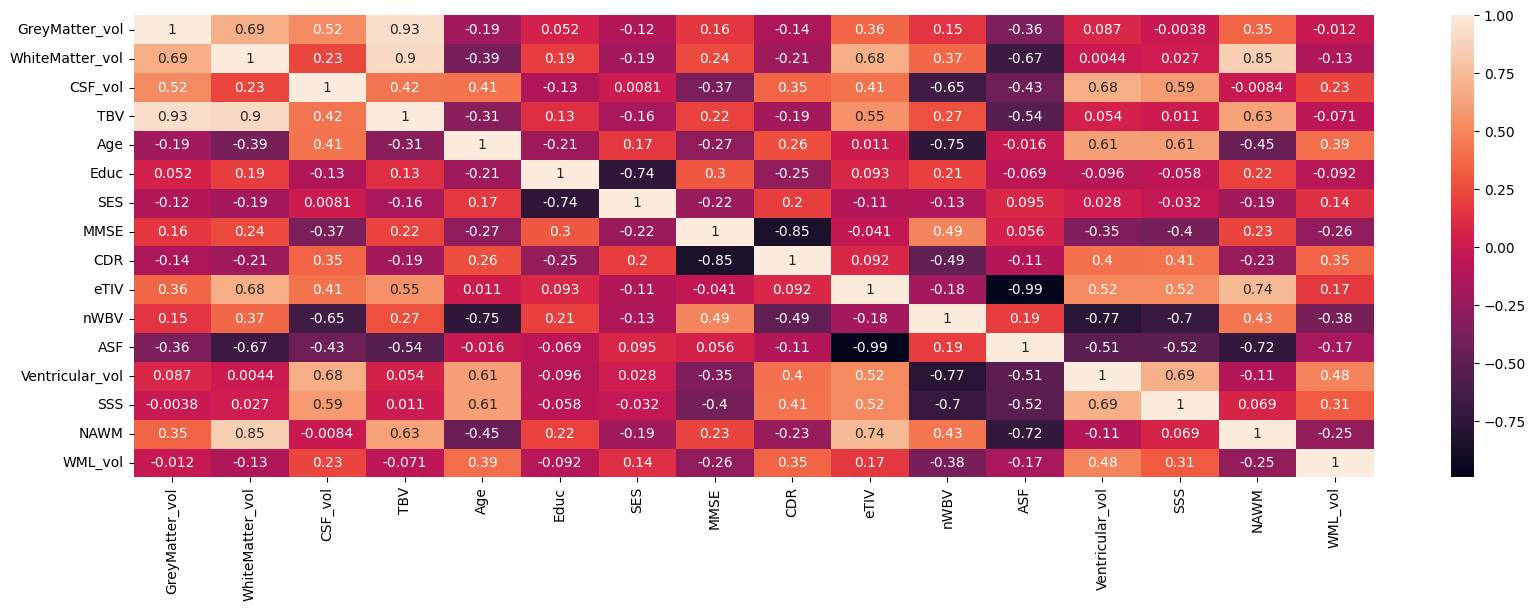

In [ ]:
# Heatmap correlation visualization
plt.figure(figsize=(20,6))
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

In [ ]:
# Encoding categorical columns
df['M/F'] = pd.get_dummies(df['M/F'], drop_first=True, dtype="float")
df['M/F'].value_counts()

,count
M/F,
0.0,114
1.0,45


In [ ]:
# Changinmg CDR to integers
df['CDR'] = df['CDR'].astype(int)

In [ ]:
# Declaring the dependent and independent variables
X = df.drop('CDR', axis=1)
y = df['CDR']

In [ ]:
# Splitting the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [ ]:
# Scaling the data
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

**MODEL TRAINING**

Four classification models; **Random Forest Classifier, XGBoost Classifier, SVC linear classifier and Logistic Regression** were employed to compare their performance and choose the best model

In [ ]:
rf = RandomForestClassifier(n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',
    n_jobs=-1,
    random_state=42,
    class_weight="balanced")
rf.fit(X_train_scaled, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=10,
                       min_samples_leaf=5, min_samples_split=10,
                       n_estimators=200, n_jobs=-1, random_state=42)

In [ ]:
rf_pred = rf.predict(X_test_scaled)

In [ ]:
rf_proba = rf_smote.predict_proba(X_test_scaled)[:,1]

In [ ]:
# Classification report of Random Forest
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.97      0.95      0.96        40
           1       0.78      0.88      0.82         8

    accuracy                           0.94        48
   macro avg       0.88      0.91      0.89        48
weighted avg       0.94      0.94      0.94        48



Our primary concern are **dementia** patient and our ability to catch actual **dementia** patients. So, **Random Forest** gave a **dementia** recall of 0.88 which is not so good -- which means 12% of actual **dementia** patients were incorrectly classified. But overall, it generted a good result.

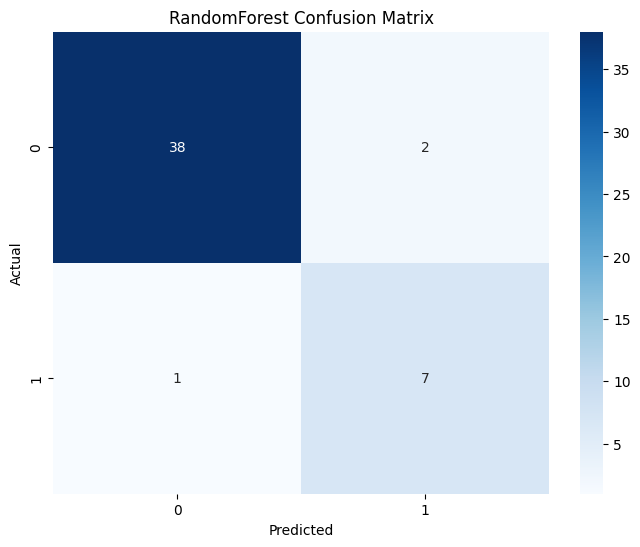

In [ ]:
# Visualizing Random Faorest Confusionm Matrix
cm = confusion_matrix(y_test, rf_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, cmap="Blues", annot=True)
plt.title("RandomForest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

This implies that:

1) **True Negatives (TN) = 38**: 38 patients who were completely healthy (Class 0) were correctly identified by the model as healthy.

2) **False Positives (FP) = 2**: 2 healthy patient was incorrectly flagged by the model as having dementia (Class 1).

3) **False Negatives (FN) = 1**: 1 patients who actually have dementia (Class 1) were missed by the model and incorrectly classified as healthy.

4) **True Positives (TP) = 7**: 7 patients who actually have dementia were successfully caught and correctly classified as having dementia by the model.

In [ ]:
xgb = XGBClassifier(n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=9,
    eval_metric='logloss',
    random_state=42,
    class_weight="balanced")
xgb.fit(X_train_scaled, y_train)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [19:04:50] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "class_weight" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              class_weight='balanced', colsample_bylevel=None,
              colsample_bynode=None, colsample_bytree=0.8, device=None,
              early_stopping_rounds=None, enable_categorical=True,
              eval_metric='logloss', feature_types=None, feature_weights=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None, ...)

In [ ]:
xgb_pred = xgb.predict(X_test_scaled)
xgb_proba = xgb.predict_proba(X_test_scaled)[:, 1]

In [ ]:
print(classification_report(y_test, xgb_pred))

              precision    recall  f1-score   support

           0       0.97      0.97      0.97        40
           1       0.88      0.88      0.88         8

    accuracy                           0.96        48
   macro avg       0.93      0.93      0.93        48
weighted avg       0.96      0.96      0.96        48



XGB Classifier gave a better dementia recall (0.88) than Random Forest and all the models which means that it correctly catches 88% of patients who had dementia and misses 12%.

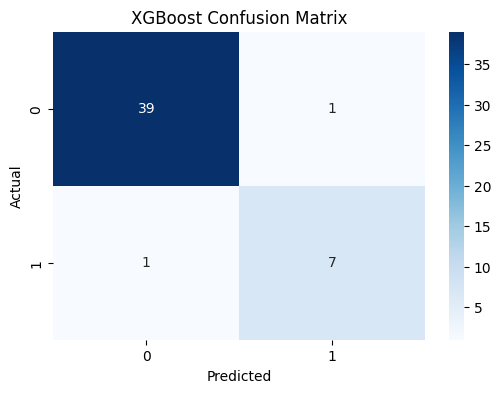

In [ ]:
cm = confusion_matrix(y_test, xgb_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, cmap="Blues", annot=True)
plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

The **confusion matrix** for **XGB Classifier** implies that:


**1.** **True Negatives (TN) = 39:** 39 patients who were completely healthy (Class 0) were correctly identified by the model as healthy.

**2.** **False Positives (FP) = 1:** 1 healthy patients were incorrectly flagged as having dementia.

**3.** **False Negatives (FN) = 1:** Only 1 single patient who actually had dementia was missed by the model.

**4.** **True Positives (TP) = 7:** 7 out of the 8 patients who actually have dementia were successfully caught by the model.


In [ ]:
svm_linear =SVC(kernel="linear", probability=True, random_state=42)
svm_linear.fit(X_train_scaled, y_train)

SVC(kernel='linear', probability=True, random_state=42)

In [ ]:
svm_linear_pred=svm_linear.predict(X_test_scaled)
svm_linear_proba=svm_linear.predict_proba(X_test_scaled)[:, 1]

In [ ]:
print(classification_report(y_test, svm_linear_pred))

              precision    recall  f1-score   support

           0       0.91      0.97      0.94        40
           1       0.80      0.50      0.62         8

    accuracy                           0.90        48
   macro avg       0.85      0.74      0.78        48
weighted avg       0.89      0.90      0.89        48



SVM linear classfication shows that the model only catched 50% of actual dementia patients, leaving the remaining 50% scott-free which is very dangerous. Although it shows an 80% precision score for dementia, recall is our primary consideration.


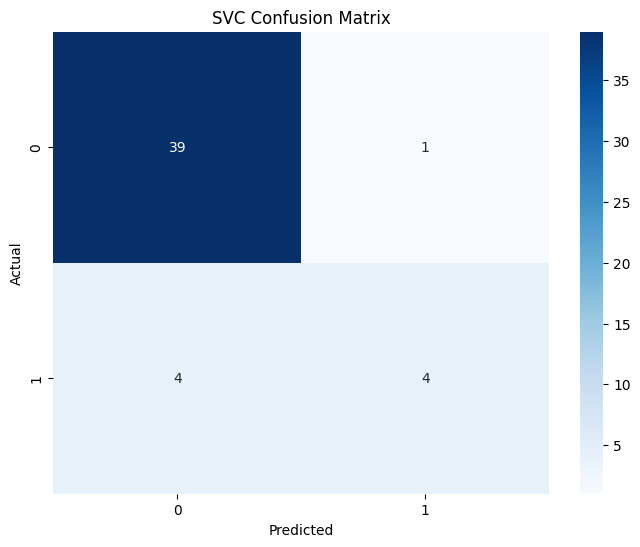

In [ ]:
cm = confusion_matrix(y_test, svm_linear_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, cmap="Blues", annot=True)
plt.title("SVC Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

SVC confusion matrix implies:

**1. True Negatives (TN) = 39:** All 39 patients who were completely healthy (Class 0) were correctly identified as healthy.

**2. False Positives (FP) = 1:** 1 healthy patients were incorrectly flagged as sick.

**3. False Negatives (FN) = 4:** 4 patients who actually have dementia were completely missed by the model.


**4. True Positives (TP) = 4:** Only 4 out of the 8 patients who actually have dementia were successfully identified.


In [ ]:
from sklearn.linear_model import  LogisticRegression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [ ]:
lr_pred = lr.predict(X_test_scaled)
lr_proba = lr.predict_proba(X_test_scaled)[:, 1]

In [ ]:
print(classification_report(y_test, lr_pred))

              precision    recall  f1-score   support

           0       0.93      1.00      0.96        40
           1       1.00      0.62      0.77         8

    accuracy                           0.94        48
   macro avg       0.97      0.81      0.87        48
weighted avg       0.94      0.94      0.93        48



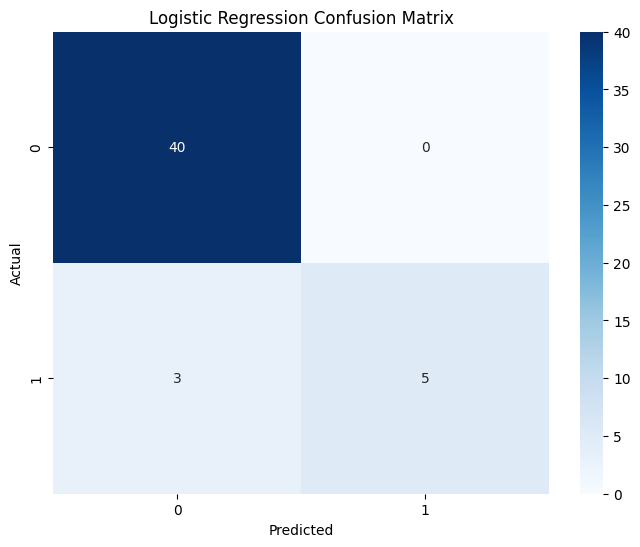

In [ ]:
cm = confusion_matrix(y_test, lr_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, cmap="Blues", annot=True)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Logistic Regression confusion matrix implies:

**1. True Negatives (TN) = 40:** All 40 patients who were completely healthy (Class 0) were correctly identified by the model as healthy.

**2. False Positives (FP) = 0:** 0 healthy patients were incorrectly flagged as sick.

**3. False Negatives (FN) = 3:** 3 patients who actually have dementia (Class 1) were completely missed by the model and incorrectly classified as healthy.

**4. True Positives (TP) = 5:** 5 out of the 8 patients who actually have dementia were successfully identified by the model.

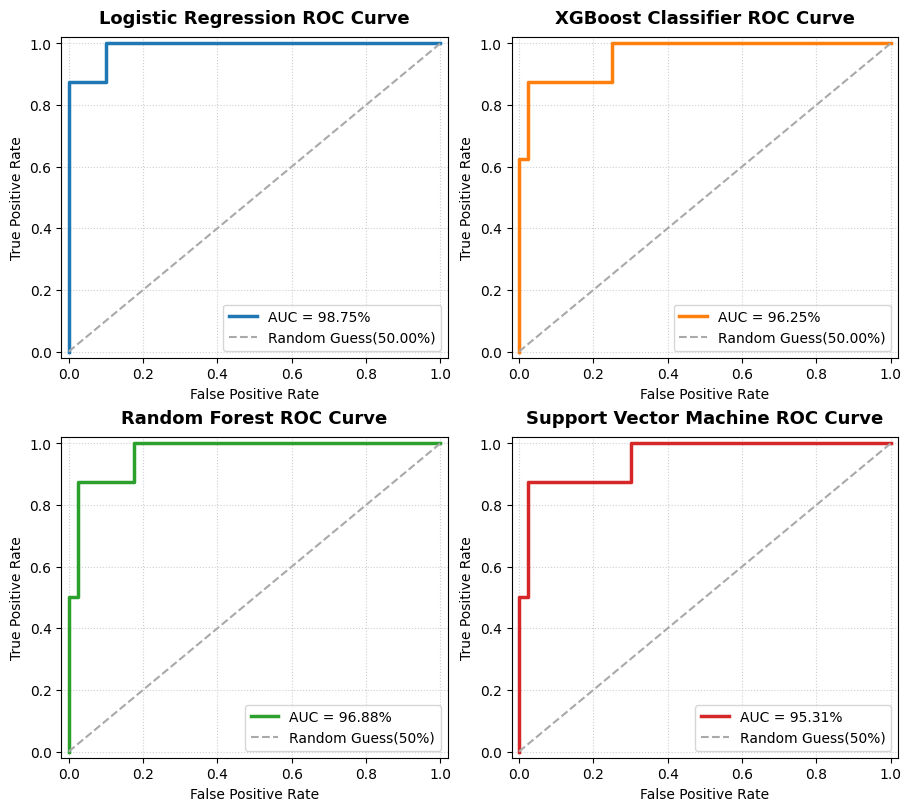

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# 1. ENFORCE STABILITY: Use layout="constrained" to stop the shaking loop entirely
fig, axes = plt.subplots(2, 2, figsize=(9, 8), layout="constrained")
axes = axes.ravel()  # Flattens the 2D grid matrix into 1D for direct indexing

# ==========================================
# SUBPLOT 0: LOGISTIC REGRESSION ROC-AUC
# ==========================================
# Extract probability score array directly from your variable
lr_proba = lr.predict_proba(X_test_scaled)[:, 1]
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_proba)
auc_lr = roc_auc_score(y_test, lr_proba)

axes[0].plot(fpr_lr, tpr_lr, color='tab:blue', lw=2.5, label=f'AUC = {auc_lr * 100:.2f}%')
axes[0].plot([0, 1], [0, 1], color='darkgray', linestyle='--', lw=1.5, label='Random Guess(50.00%)')
axes[0].set_title('Logistic Regression ROC Curve', fontsize=13, weight='bold', pad=10)
axes[0].set_xlabel('False Positive Rate', fontsize=10)
axes[0].set_ylabel('True Positive Rate', fontsize=10)
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='lower right', fontsize=10)

# ==========================================
# SUBPLOT 1: XGBOOST CLASSIFIER ROC-AUC
# ==========================================
# Extract probability score array directly from your variable
xgb_proba = xgb.predict_proba(X_test_scaled)[:, 1]
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_proba)
auc_xgb = roc_auc_score(y_test, xgb_proba)

axes[1].plot(fpr_xgb, tpr_xgb, color='tab:orange', lw=2.5, label=f'AUC = {auc_xgb * 100:.2f}%')
axes[1].plot([0, 1], [0, 1], color='darkgray', linestyle='--', lw=1.5, label='Random Guess(50.00%)')
axes[1].set_title('XGBoost Classifier ROC Curve', fontsize=13, weight='bold', pad=10)
axes[1].set_xlabel('False Positive Rate', fontsize=10)
axes[1].set_ylabel('True Positive Rate', fontsize=10)
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(loc='lower right', fontsize=10)

# ==========================================
# SUBPLOT 2: RANDOM FOREST ROC-AUC
# ==========================================
# Extract probability score array directly from your variable
rf_proba = rf.predict_proba(X_test_scaled)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_proba)
auc_rf = roc_auc_score(y_test, rf_proba)

axes[2].plot(fpr_rf, tpr_rf, color='tab:green', lw=2.5, label=f'AUC = {auc_rf * 100:.2f}%')
axes[2].plot([0, 1], [0, 1], color='darkgray', linestyle='--', lw=1.5, label='Random Guess(50%)')
axes[2].set_title('Random Forest ROC Curve', fontsize=13, weight='bold', pad=10)
axes[2].set_xlabel('False Positive Rate', fontsize=10)
axes[2].set_ylabel('True Positive Rate', fontsize=10)
axes[2].grid(True, linestyle=':', alpha=0.6)
axes[2].legend(loc='lower right', fontsize=10)

# ==========================================
# SUBPLOT 3: SUPPORT VECTOR MACHINE ROC-AUC
# ==========================================
# Extract probability score array directly from your variable
svm_proba = svm_linear.predict_proba(X_test_scaled)[:, 1]
fpr_svm, tpr_svm, _ = roc_curve(y_test, svm_proba)
auc_svm = roc_auc_score(y_test, svm_proba)

axes[3].plot(fpr_svm, tpr_svm, color='tab:red', lw=2.5, label=f'AUC = {auc_svm * 100:.2f}%')
axes[3].plot([0, 1], [0, 1], color='darkgray', linestyle='--', lw=1.5, label='Random Guess(50%)')
axes[3].set_title('Support Vector Machine ROC Curve', fontsize=13, weight='bold', pad=10)
axes[3].set_xlabel('False Positive Rate', fontsize=10)
axes[3].set_ylabel('True Positive Rate', fontsize=10)
axes[3].grid(True, linestyle=':', alpha=0.6)
axes[3].legend(loc='lower right', fontsize=10)

# 4. Enforce strict safety viewing boundaries across all 4 window charts
for ax in axes:
    ax.set_xlim([-0.02, 1.02])
    ax.set_ylim([-0.02, 1.02])

# 5. Render the plots statically
plt.show()





**📈 Logistic Regression (AUC = 98.75%)**

• The Graph Shape: It shows a very smooth, mathematically ideal arc that rapidly climbs straight up the Y-axis.
• Clinical Meaning: It has the highest overall statistical separation power. It achieves a perfect 100% detection rate (True Positive Rate = 1.0) once it allows a minor False Positive Rate of about 0.15.


**📈 XGBoost Classifier (AUC = 96.25%)**

• The Graph Shape: It features a highly aggressive, steep vertical climb right at the very beginning of the X-axis before transitioning into a "stepped" line.
• Clinical Meaning: This steep initial climb is exactly what you want in a clinical screening tool. It proves that XGBoost can successfully capture your target dementia cases (7 out of 8) while keeping false alarms almost at absolute zero. The jagged steps appear because it is a tree-based ensemble method making categorical splits on your features (like WML_vol and Ventricular_vol).


**📈 Random Forest (AUC = 96.88%)**

• The Graph Shape: It has the exact same total area score as XGBoost but features slightly wider, blockier steps.
• Clinical Meaning: It provides strong classification, but its threshold transitions are slightly less refined than XGBoost's boosting iterations, matching the exact drop in sensitivity we saw in the confusion matrices.


**📈 Support Vector Machine (AUC = 95.31%)**

• The Graph Shape: It has the lowest overall AUC of the group. Its curve is noticeably flatter and shifts further to the right before it arches upward.
• Clinical Meaning: This visual gap reflects its conservative linear boundary. It requires a much higher False Positive Rate (0.28) before it can safely alter its thresholds enough to catch the remaining dementia cases, mirroring its low 50% baseline recall.

In [ ]:
feature_importance = pd.DataFrame({
    "Feature" : X.columns,
    "Importance" : xgb.feature_importances_
}).sort_values(ascending=False, by="Importance")
display(feature_importance.head(10))

,Feature,Importance
8,MMSE,0.261493
10,nWBV,0.219080
13,SSS,0.084650
12,Ventricular_vol,0.075461
14,NAWM,0.065954
2,CSF_vol,0.063667
5,Age,0.045748
0,GreyMatter_vol,0.043454
9,eTIV,0.042780
15,WML_vol,0.038404


In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_scaled)

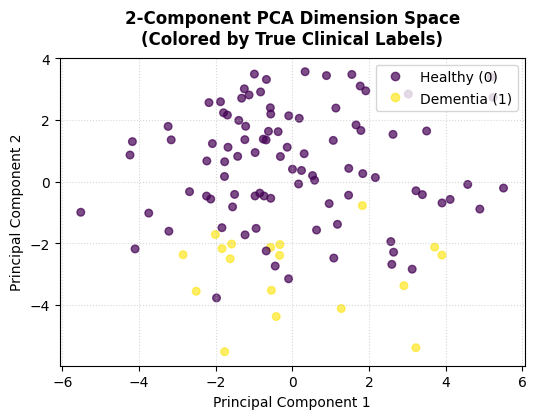

In [ ]:
import matplotlib.pyplot as plt

# 1. FIX THE SHAKING & CANVAS SIZE: Scale to (8, 6) to stay safely within Colab's viewport
plt.figure(figsize=(6, 4))

# 2. Plot the PCA components and color them dynamically by your TRUE clinical labels (y_train_smote)
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=y_train, cmap="viridis", alpha=0.7, s=30
)

# 3. Add an automated, professional legend matching your true targets (0.0 vs 1.0)
plt.legend(handles=scatter.legend_elements()[0], labels=["Healthy (0)", "Dementia (1)"], loc="upper right")

# 4. Customize academic chart labels
plt.title('2-Component PCA Dimension Space\n(Colored by True Clinical Labels)', fontsize=12, weight='bold', pad=10)
plt.xlabel("Principal Component 1", fontsize=10)
plt.ylabel("Principal Component 2", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.5)

plt.show()
